# 01. Dataset Exploration and Validation

## Multimodal Medicinal Plant Leaf Retrieval
### Using Visual and Textual Features

---

## 1. Overview

This notebook performs Exploratory Data Analysis (EDA)
and validation of a multimodal medicinal plant leaf dataset
consisting of leaf images and textual descriptions.

## 2. Objectives

- Analyze dataset structure and completeness.
- Validate image and text associations.
- Analyze class distribution.
- Examine image dimensions and quality.
- Detect duplicate and corrupted images.
- Analyze textual descriptions.
- Identify potential data quality issues before preprocessing.

## 3. Dataset Modalities

**Image modality:**
- Medicinal plant leaf images.
- Front-view and back-view images.

**Text modality:**
- Leaf color.
- Leaf shape.
- Leaf margin.
- Leaf tip.
- Leaf texture.
- Complete morphological descriptions.

## 4. Plant Classes

1. Mangkok
2. Salam
3. Sambang Darah
4. Sirih
5. Tapak Kuda

## 5. Expected Output

A validated multimodal dataset ready for the
data preprocessing and feature extraction stages.

In [1]:
# ==================================================
# IMPORT LIBRARIES
# ==================================================

# Data manipulation and numerical computation
import pandas as pd
import numpy as np

# File and directory management
import os
from pathlib import Path

# Image processing
import cv2
from PIL import Image

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Duplicate image detection
import hashlib

# Text analysis
from collections import Counter

# Notebook display
from IPython.display import display

# Visualization configuration
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# ==================================================
# DATASET PATH CONFIGURATION
# ==================================================

# Determine project root directory
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Dataset directories
DATASET_DIR = PROJECT_ROOT / "dataset"
RAW_DIR = DATASET_DIR / "raw"
PROCESSED_DIR = DATASET_DIR / "processed"

# Metadata files
METADATA_CSV = DATASET_DIR / "metadata.csv"
METADATA_XLSX = DATASET_DIR / "metadata.xlsx"

# Output directories
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
METRICS_DIR = RESULTS_DIR / "metrics"
MODELS_DIR = PROJECT_ROOT / "models"

# Display path configuration
print("PROJECT PATH CONFIGURATION")
print("=" * 60)

paths = {
    "Project Root": PROJECT_ROOT,
    "Dataset Directory": DATASET_DIR,
    "Raw Images": RAW_DIR,
    "Processed Directory": PROCESSED_DIR,
    "Metadata CSV": METADATA_CSV,
    "Metadata Excel": METADATA_XLSX,
    "Figures Directory": FIGURES_DIR,
    "Metrics Directory": METRICS_DIR,
    "Models Directory": MODELS_DIR
}

for name, path in paths.items():
    status = "OK" if path.exists() else "NOT FOUND"
    print(f"[{status}] {name}")
    print(f"    {path}")

print("=" * 60)

if all(path.exists() for path in paths.values()):
    print("All project paths are valid!")
else:
    print("Warning: Some paths could not be found.")

PROJECT PATH CONFIGURATION
[OK] Project Root
    d:\Project\Multimodal_Leaf_Retrieval
[OK] Dataset Directory
    d:\Project\Multimodal_Leaf_Retrieval\dataset
[OK] Raw Images
    d:\Project\Multimodal_Leaf_Retrieval\dataset\raw
[OK] Processed Directory
    d:\Project\Multimodal_Leaf_Retrieval\dataset\processed
[OK] Metadata CSV
    d:\Project\Multimodal_Leaf_Retrieval\dataset\metadata.csv
[OK] Metadata Excel
    d:\Project\Multimodal_Leaf_Retrieval\dataset\metadata.xlsx
[OK] Figures Directory
    d:\Project\Multimodal_Leaf_Retrieval\results\figures
[OK] Metrics Directory
    d:\Project\Multimodal_Leaf_Retrieval\results\metrics
[OK] Models Directory
    d:\Project\Multimodal_Leaf_Retrieval\models
All project paths are valid!


In [3]:
# ==================================================
# LOAD METADATA
# ==================================================

# Load metadata CSV
df = pd.read_csv(METADATA_CSV, encoding="utf-8-sig")

# Display dataset information
print("METADATA INFORMATION")
print("=" * 60)

print(f"Total records : {df.shape[0]}")
print(f"Total columns : {df.shape[1]}")
print(f"Dataset shape : {df.shape}")

# Display column names
print("\nCOLUMN NAMES")
print("=" * 60)

for i, column in enumerate(df.columns, start=1):
    print(f"{i:2d}. {column}")

# Display first five records
print("\nFIRST 5 RECORDS")
print("=" * 60)

display(df.head())

# Display data types
print("\nDATA TYPES")
print("=" * 60)

display(df.dtypes.to_frame(name="Data Type"))

METADATA INFORMATION
Total records : 105
Total columns : 11
Dataset shape : (105, 11)

COLUMN NAMES
 1. nama_file
 2. image_path
 3. kelas
 4. tampilan_daun
 5. warna
 6. bentuk
 7. tepi
 8. ujung
 9. tekstur
10. deskripsi_lengkap
11. catatan_verifikasi

FIRST 5 RECORDS


,nama_file,image_path,kelas,tampilan_daun,warna,bentuk,tepi,ujung,tekstur,deskripsi_lengkap,catatan_verifikasi
0,mangkok 10.jpeg,dataset/daun_mangkok/foto belakang/mangkok 10....,Mangkok,belakang,hijau tua,membulat,bergelombang halus,membulat,"mengilap, berkerut, tulang daun tampak","Daun berwarna hijau tua, berbentuk membulat, d...",Tampilan mengikuti folder; verifikasi sisi dau...
1,mangkok 11.png,dataset/daun_mangkok/foto belakang/mangkok 11.png,Mangkok,belakang,hijau kekuningan,membulat menyerupai hati,bergelombang halus,membulat,"kusam, tulang daun menonjol, sedikit berkerut","Daun berwarna hijau kekuningan, berbentuk memb...",NaN
2,mangkok 12.png,dataset/daun_mangkok/foto belakang/mangkok 12.png,Mangkok,belakang,hijau zaitun,membulat,bergelombang halus,membulat,"kusam, berkerut halus, tulang daun terlihat","Daun berwarna hijau zaitun, berbentuk membulat...",NaN
3,mangkok 13.png,dataset/daun_mangkok/foto belakang/mangkok 13.png,Mangkok,belakang,hijau sedang,membulat menyerupai hati,bergelombang halus,membulat,"kusam, tulang daun menonjol","Daun berwarna hijau sedang, berbentuk membulat...",NaN
4,mangkok 14.png,dataset/daun_mangkok/foto belakang/mangkok 14.png,Mangkok,belakang,hijau kekuningan,membulat menyerupai hati,bergelombang halus,membulat,"kusam, urat daun bercabang terlihat","Daun berwarna hijau kekuningan, berbentuk memb...",NaN



DATA TYPES


,Data Type
nama_file,str
image_path,str
kelas,str
tampilan_daun,str
warna,str
bentuk,str
tepi,str
ujung,str
tekstur,str
deskripsi_lengkap,str


In [4]:
# ==================================================
# VALIDATE METADATA STRUCTURE
# ==================================================

print("METADATA STRUCTURE VALIDATION")
print("=" * 60)

# 1. Validate required columns
required_columns = [
    "nama_file",
    "image_path",
    "kelas",
    "tampilan_daun",
    "warna",
    "bentuk",
    "tepi",
    "ujung",
    "tekstur",
    "deskripsi_lengkap",
    "catatan_verifikasi"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

print("\n1. COLUMN VALIDATION")

if not missing_columns:
    print("[OK] All required columns are available.")
else:
    raise ValueError(f"Missing columns: {missing_columns}")


# 2. Check missing values and empty strings
print("\n2. MISSING AND EMPTY VALUES")

missing_values = df.isna().sum()

empty_values = df.apply(
    lambda col: col.map(
        lambda x: isinstance(x, str) and x.strip() == ""
    ).sum()
)

validation_table = pd.DataFrame({
    "Missing Values": missing_values,
    "Empty Strings": empty_values
})

validation_table["Total"] = (
    validation_table["Missing Values"]
    + validation_table["Empty Strings"]
)

display(validation_table)


# 3. Validate duplicate metadata
print("\n3. DUPLICATE METADATA")

duplicate_rows = df.duplicated().sum()

duplicate_paths = df.duplicated(
    subset=["image_path"]
).sum()

print(f"Duplicate rows        : {duplicate_rows}")
print(f"Duplicate image paths : {duplicate_paths}")

if duplicate_paths > 0:
    display(
        df[df.duplicated(
            subset=["image_path"],
            keep=False
        )]
    )


# 4. Validate class labels
print("\n4. CLASS LABEL VALIDATION")

expected_classes = {
    "Mangkok",
    "Salam",
    "Sambang Darah",
    "Sirih",
    "Tapak Kuda"
}

actual_classes = set(df["kelas"].dropna().unique())

unexpected_classes = actual_classes - expected_classes
missing_classes = expected_classes - actual_classes

print(f"Expected classes   : {len(expected_classes)}")
print(f"Actual classes     : {len(actual_classes)}")
print(f"Unexpected classes : {unexpected_classes}")
print(f"Missing classes    : {missing_classes}")

if not unexpected_classes and not missing_classes:
    print("[OK] All class labels are valid.")


# 5. Validate essential retrieval columns
print("\n5. ESSENTIAL COLUMN VALIDATION")

essential_columns = [
    "nama_file",
    "image_path",
    "kelas",
    "tampilan_daun",
    "deskripsi_lengkap"
]

essential_issues = validation_table.loc[
    essential_columns, "Total"
].sum()

if essential_issues == 0:
    print("[OK] All essential columns are complete.")
else:
    print(f"[WARNING] Found {essential_issues} missing or empty values.")


# 6. Validation summary
print("\n6. VALIDATION SUMMARY")
print("=" * 60)

if (
    essential_issues == 0
    and duplicate_rows == 0
    and duplicate_paths == 0
    and not unexpected_classes
    and not missing_classes
):
    print("[PASS] Metadata structure validation successful.")
else:
    print("[WARNING] Metadata requires further inspection.")

METADATA STRUCTURE VALIDATION

1. COLUMN VALIDATION
[OK] All required columns are available.

2. MISSING AND EMPTY VALUES


,Missing Values,Empty Strings,Total
nama_file,0,0,0
image_path,0,0,0
kelas,0,0,0
tampilan_daun,0,0,0
warna,0,0,0
bentuk,0,0,0
tepi,0,0,0
ujung,0,0,0
tekstur,0,0,0
deskripsi_lengkap,0,0,0



3. DUPLICATE METADATA
Duplicate rows        : 0
Duplicate image paths : 0

4. CLASS LABEL VALIDATION
Expected classes   : 5
Actual classes     : 5
Unexpected classes : set()
Missing classes    : set()
[OK] All class labels are valid.

5. ESSENTIAL COLUMN VALIDATION
[OK] All essential columns are complete.

6. VALIDATION SUMMARY
[PASS] Metadata structure validation successful.


In [5]:
# ==================================================
# VALIDATE IMAGE PATHS
# ==================================================

print("IMAGE PATH VALIDATION")
print("=" * 60)

# 1. Adjust image paths to the new dataset structure
def resolve_image_path(image_path):
    relative_path = Path(str(image_path))

    if relative_path.parts[:2] == ("dataset", "raw"):
        return PROJECT_ROOT / relative_path

    if relative_path.parts[:1] == ("dataset",):
        relative_path = Path(*relative_path.parts[1:])

    return RAW_DIR / relative_path


# Create absolute image paths
df["absolute_image_path"] = df["image_path"].apply(
    resolve_image_path
)

# 2. Check whether each image file exists
df["image_exists"] = df["absolute_image_path"].apply(
    lambda path: path.is_file()
)

# 3. Calculate validation results
total_images = len(df)
valid_images = int(df["image_exists"].sum())
missing_images = total_images - valid_images

print("\n1. IMAGE PATH SUMMARY")
print(f"Total metadata records : {total_images}")
print(f"Valid image paths      : {valid_images}")
print(f"Missing image paths    : {missing_images}")

# 4. Display missing images
print("\n2. MISSING IMAGE FILES")

if missing_images == 0:
    print("[OK] All metadata records have matching image files.")
else:
    display(
        df.loc[
            ~df["image_exists"],
            ["nama_file", "kelas", "absolute_image_path"]
        ]
    )

# 5. Check actual image files in the dataset folder
valid_extensions = {".jpg", ".jpeg", ".png"}

actual_image_files = {
    path.resolve()
    for path in RAW_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in valid_extensions
}

registered_image_files = {
    path.resolve()
    for path in df.loc[
        df["image_exists"], "absolute_image_path"
    ]
}

# Identify images without metadata
unregistered_images = (
    actual_image_files - registered_image_files
)

print("\n3. DATASET CONSISTENCY")

print(f"Actual image files     : {len(actual_image_files)}")
print(f"Registered image files : {len(registered_image_files)}")
print(f"Unregistered images    : {len(unregistered_images)}")

if unregistered_images:
    display(
        pd.DataFrame({
            "Unregistered Image": [
                str(path)
                for path in sorted(unregistered_images)
            ]
        })
    )

# 6. Display sample validated image paths
print("\n4. SAMPLE VALIDATED IMAGE PATHS")

display(
    df[
        [
            "nama_file",
            "kelas",
            "absolute_image_path",
            "image_exists"
        ]
    ].head()
)

# 7. Final validation summary
print("\n5. VALIDATION SUMMARY")
print("=" * 60)

if (
    missing_images == 0
    and len(unregistered_images) == 0
    and len(registered_image_files) == total_images
):
    print("[PASS] All images and metadata are correctly associated.")
else:
    print("[WARNING] Dataset requires further inspection.")

IMAGE PATH VALIDATION

1. IMAGE PATH SUMMARY
Total metadata records : 105
Valid image paths      : 105
Missing image paths    : 0

2. MISSING IMAGE FILES
[OK] All metadata records have matching image files.

3. DATASET CONSISTENCY
Actual image files     : 105
Registered image files : 105
Unregistered images    : 0

4. SAMPLE VALIDATED IMAGE PATHS


,nama_file,kelas,absolute_image_path,image_exists
0,mangkok 10.jpeg,Mangkok,d:\Project\Multimodal_Leaf_Retrieval\dataset\r...,True
1,mangkok 11.png,Mangkok,d:\Project\Multimodal_Leaf_Retrieval\dataset\r...,True
2,mangkok 12.png,Mangkok,d:\Project\Multimodal_Leaf_Retrieval\dataset\r...,True
3,mangkok 13.png,Mangkok,d:\Project\Multimodal_Leaf_Retrieval\dataset\r...,True
4,mangkok 14.png,Mangkok,d:\Project\Multimodal_Leaf_Retrieval\dataset\r...,True



5. VALIDATION SUMMARY
[PASS] All images and metadata are correctly associated.


CLASS DISTRIBUTION ANALYSIS

1. CLASS DISTRIBUTION TABLE


,Number of Images,Percentage (%)
Class,,
Mangkok,20,19.05
Salam,20,19.05
Sambang Darah,20,19.05
Sirih,20,19.05
Tapak Kuda,25,23.81



2. DATASET STATISTICS
Total images       : 105
Total classes      : 5
Minimum per class  : 20
Maximum per class  : 25
Average per class  : 21.00
Imbalance ratio    : 1.25


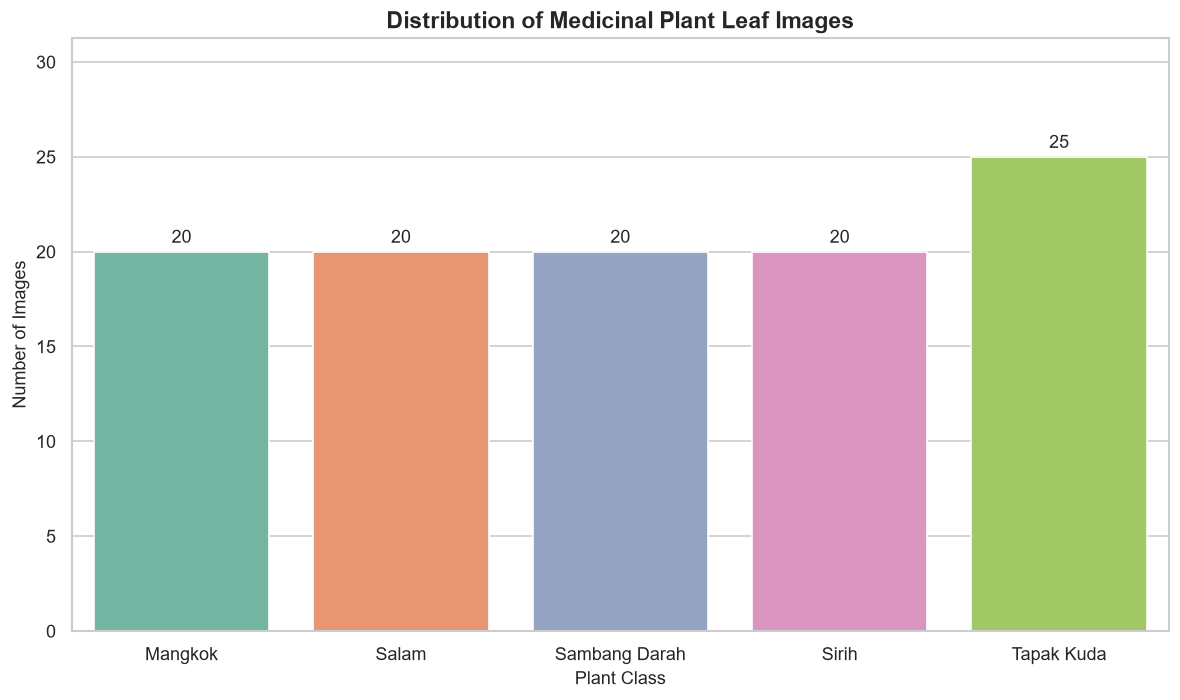


3. ANALYSIS SUMMARY
Class imbalance ratio: 1.25
Review the distribution before evaluation.

Class distribution results saved successfully!


In [6]:
# ==================================================
# CLASS DISTRIBUTION
# ==================================================

print("CLASS DISTRIBUTION ANALYSIS")
print("=" * 60)

# 1. Count images per class
class_counts = (
    df["kelas"]
    .value_counts()
    .sort_index()
)

# 2. Calculate percentage per class
class_percentage = (
    class_counts / class_counts.sum() * 100
)

# 3. Create distribution table
class_distribution = pd.DataFrame({
    "Number of Images": class_counts,
    "Percentage (%)": class_percentage.round(2)
})

class_distribution.index.name = "Class"

print("\n1. CLASS DISTRIBUTION TABLE")
display(class_distribution)

# 4. Dataset statistics
print("\n2. DATASET STATISTICS")
print(f"Total images       : {class_counts.sum()}")
print(f"Total classes      : {len(class_counts)}")
print(f"Minimum per class  : {class_counts.min()}")
print(f"Maximum per class  : {class_counts.max()}")
print(f"Average per class  : {class_counts.mean():.2f}")

# 5. Calculate imbalance ratio
imbalance_ratio = class_counts.max() / class_counts.min()

print(f"Imbalance ratio    : {imbalance_ratio:.2f}")

# 6. Visualize class distribution
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    hue=class_counts.index,
    palette="Set2",
    legend=False
)

# Add value labels
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=11)

plt.title(
    "Distribution of Medicinal Plant Leaf Images",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Plant Class", fontsize=11)
plt.ylabel("Number of Images", fontsize=11)

plt.ylim(0, class_counts.max() * 1.25)
plt.tight_layout()

# Save visualization
plt.savefig(
    FIGURES_DIR / "01_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 7. Save distribution table
class_distribution.to_csv(
    METRICS_DIR / "01_class_distribution.csv"
)

print("\n3. ANALYSIS SUMMARY")
print("=" * 60)

if imbalance_ratio == 1:
    print("[OK] The dataset is perfectly balanced.")
else:
    print(f"Class imbalance ratio: {imbalance_ratio:.2f}")
    print("Review the distribution before evaluation.")

print("\nClass distribution results saved successfully!")

LEAF VIEW DISTRIBUTION ANALYSIS

1. OVERALL LEAF VIEW DISTRIBUTION


,Number of Images,Percentage (%)
tampilan_daun,,
depan,55,52.38
belakang,50,47.62



2. LEAF VIEW DISTRIBUTION PER CLASS


tampilan_daun,belakang,depan
kelas,,
Mangkok,10,10
Salam,10,10
Sambang Darah,10,10
Sirih,10,10
Tapak Kuda,10,15



3. LEAF VIEW VALIDATION
[OK] All leaf view labels are valid.


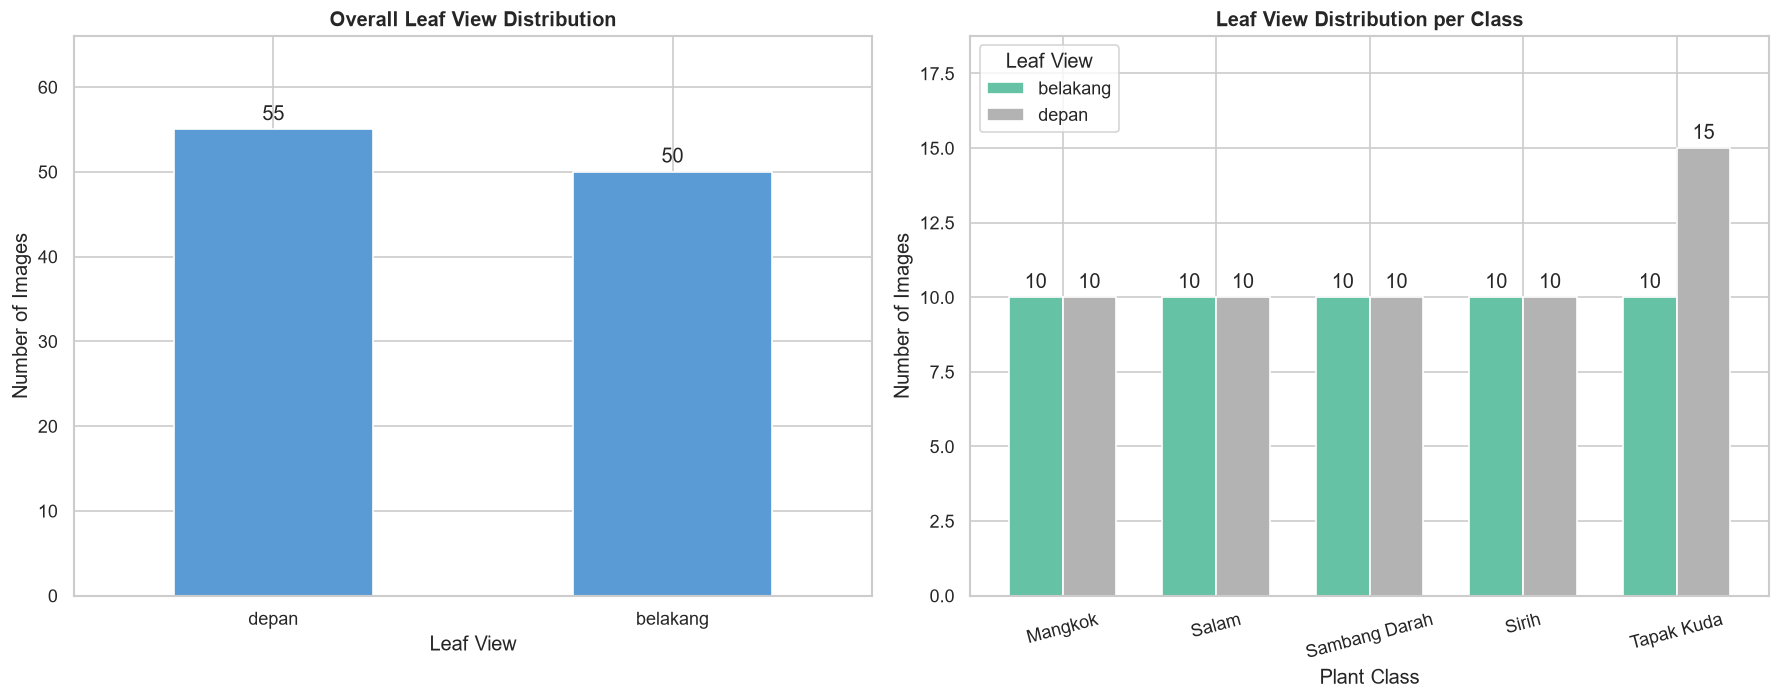


4. ANALYSIS SUMMARY
Total images     : 105
Front-view images: 55
Back-view images : 50

Leaf view distribution results saved successfully!


In [7]:
# ==================================================
# LEAF VIEW DISTRIBUTION
# ==================================================

print("LEAF VIEW DISTRIBUTION ANALYSIS")
print("=" * 60)

# 1. Normalize leaf view labels
leaf_views = (
    df["tampilan_daun"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "foto depan": "depan",
        "foto belakang": "belakang",
        "front": "depan",
        "back": "belakang",
        "front view": "depan",
        "back view": "belakang"
    })
    .fillna("unknown")
)

# 2. Count images based on leaf view
view_counts = leaf_views.value_counts()

view_distribution = pd.DataFrame({
    "Number of Images": view_counts,
    "Percentage (%)": (
        view_counts / len(df) * 100
    ).round(2)
})

print("\n1. OVERALL LEAF VIEW DISTRIBUTION")
display(view_distribution)

# 3. Analyze leaf view distribution per class
class_view_distribution = pd.crosstab(
    df["kelas"],
    leaf_views
)

print("\n2. LEAF VIEW DISTRIBUTION PER CLASS")
display(class_view_distribution)

# 4. Validate leaf view labels
expected_views = {"depan", "belakang"}
actual_views = set(leaf_views.unique())

unexpected_views = actual_views - expected_views

print("\n3. LEAF VIEW VALIDATION")

if not unexpected_views:
    print("[OK] All leaf view labels are valid.")
else:
    print(f"[WARNING] Unexpected labels: {unexpected_views}")

# 5. Visualize leaf view distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Overall distribution
view_counts.plot(
    kind="bar",
    ax=axes[0],
    color="#5B9BD5",
    rot=0
)

axes[0].set_title(
    "Overall Leaf View Distribution",
    fontweight="bold"
)

axes[0].set_xlabel("Leaf View")
axes[0].set_ylabel("Number of Images")
axes[0].set_ylim(0, view_counts.max() * 1.2)

for container in axes[0].containers:
    axes[0].bar_label(container, padding=3)

# Distribution per class
class_view_distribution.plot(
    kind="bar",
    ax=axes[1],
    colormap="Set2",
    width=0.7,
    rot=15
)

axes[1].set_title(
    "Leaf View Distribution per Class",
    fontweight="bold"
)

axes[1].set_xlabel("Plant Class")
axes[1].set_ylabel("Number of Images")
axes[1].set_ylim(
    0,
    class_view_distribution.to_numpy().max() * 1.25
)

axes[1].legend(title="Leaf View")

for container in axes[1].containers:
    axes[1].bar_label(container, padding=3)

plt.tight_layout()

# 6. Save visualization
plt.savefig(
    FIGURES_DIR / "02_leaf_view_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 7. Save analysis results
view_distribution.to_csv(
    METRICS_DIR / "02_leaf_view_distribution.csv"
)

class_view_distribution.to_csv(
    METRICS_DIR / "03_class_view_distribution.csv"
)

# 8. Analysis summary
print("\n4. ANALYSIS SUMMARY")
print("=" * 60)

print(f"Total images     : {len(df)}")
print(f"Front-view images: {leaf_views.eq('depan').sum()}")
print(f"Back-view images : {leaf_views.eq('belakang').sum()}")

print("\nLeaf view distribution results saved successfully!")

In [8]:
# ==================================================
# CORRUPTED IMAGE DETECTION
# ==================================================

print("CORRUPTED IMAGE DETECTION")
print("=" * 60)

# 1. Function to validate image integrity
def validate_image(image_path):
    try:
        # Check file availability
        if not image_path.is_file():
            return "Missing", "Image file not found"

        # Verify image integrity using PIL
        with Image.open(image_path) as img:
            img.verify()

        # Check whether image pixels can be decoded
        with Image.open(image_path) as img:
            img.load()

        # Check image readability using OpenCV
        image_bytes = np.fromfile(
            str(image_path),
            dtype=np.uint8
        )

        image = cv2.imdecode(
            image_bytes,
            cv2.IMREAD_COLOR
        )

        if image is None or image.size == 0:
            return "Corrupted", "OpenCV cannot decode image"

        return "Valid", ""

    except Exception as error:
        return "Corrupted", str(error)


# 2. Validate all images
validation_results = df["absolute_image_path"].apply(
    validate_image
)

df["image_status"] = validation_results.apply(
    lambda result: result[0]
)

df["image_error"] = validation_results.apply(
    lambda result: result[1]
)


# 3. Calculate validation statistics
total_images = len(df)

valid_count = df["image_status"].eq("Valid").sum()

corrupted_count = df["image_status"].eq(
    "Corrupted"
).sum()

missing_count = df["image_status"].eq(
    "Missing"
).sum()

print("\n1. IMAGE VALIDATION SUMMARY")
print(f"Total images     : {total_images}")
print(f"Valid images     : {valid_count}")
print(f"Corrupted images : {corrupted_count}")
print(f"Missing images   : {missing_count}")


# 4. Create validation table
image_validation_summary = pd.DataFrame({
    "Status": ["Valid", "Corrupted", "Missing"],
    "Number of Images": [
        valid_count,
        corrupted_count,
        missing_count
    ]
})

image_validation_summary["Percentage (%)"] = (
    image_validation_summary["Number of Images"]
    / total_images * 100
).round(2)

print("\n2. IMAGE VALIDATION TABLE")
display(image_validation_summary)


# 5. Display problematic images
problematic_images = df[
    df["image_status"] != "Valid"
]

print("\n3. PROBLEMATIC IMAGES")

if problematic_images.empty:
    print("[OK] No corrupted or missing images detected.")

else:
    display(
        problematic_images[
            [
                "nama_file",
                "kelas",
                "image_path",
                "image_status",
                "image_error"
            ]
        ]
    )


# 6. Save validation results
image_validation_summary.to_csv(
    METRICS_DIR / "04_image_validation_summary.csv",
    index=False
)

df[
    [
        "nama_file",
        "kelas",
        "image_path",
        "image_status",
        "image_error"
    ]
].to_csv(
    METRICS_DIR / "05_image_validation_details.csv",
    index=False
)


# 7. Final validation summary
print("\n4. VALIDATION SUMMARY")
print("=" * 60)

if corrupted_count == 0 and missing_count == 0:
    print("[PASS] All images are valid and readable.")
else:
    print("[WARNING] Some images require further inspection.")

print("\nImage validation results saved successfully!")

CORRUPTED IMAGE DETECTION

1. IMAGE VALIDATION SUMMARY
Total images     : 105
Valid images     : 105
Corrupted images : 0
Missing images   : 0

2. IMAGE VALIDATION TABLE


,Status,Number of Images,Percentage (%)
0,Valid,105,100.0
1,Corrupted,0,0.0
2,Missing,0,0.0



3. PROBLEMATIC IMAGES
[OK] No corrupted or missing images detected.

4. VALIDATION SUMMARY
[PASS] All images are valid and readable.

Image validation results saved successfully!


IMAGE RESOLUTION ANALYSIS

1. IMAGE DIMENSION SAMPLES


,nama_file,kelas,image_width,image_height,aspect_ratio,resolution
0,mangkok 10.jpeg,Mangkok,960,1280,0.75,960 x 1280
1,mangkok 11.png,Mangkok,1254,1254,1.00,1254 x 1254
2,mangkok 12.png,Mangkok,1254,1254,1.00,1254 x 1254
3,mangkok 13.png,Mangkok,1254,1254,1.00,1254 x 1254
4,mangkok 14.png,Mangkok,1254,1254,1.00,1254 x 1254
5,mangkok 15.png,Mangkok,1254,1254,1.00,1254 x 1254
6,mangkok 6.jpeg,Mangkok,960,1280,0.75,960 x 1280
7,mangkok 7.jpeg,Mangkok,960,1280,0.75,960 x 1280
8,mangkok 8.jpeg,Mangkok,960,1280,0.75,960 x 1280
9,mangkok 9.jpeg,Mangkok,960,1280,0.75,960 x 1280



2. IMAGE DIMENSION STATISTICS


,image_width,image_height,aspect_ratio
count,105.000,105.000,105.000
mean,989.333,1183.619,0.850
std,280.489,315.392,0.119
min,224.000,224.000,0.750
25%,960.000,1254.000,0.750
50%,960.000,1280.000,0.750
75%,1254.000,1280.000,1.000
max,1254.000,1402.000,1.000



3. RESOLUTION DISTRIBUTION


,Number of Images,Percentage (%)
resolution,,
960 x 1280,55,52.38
1254 x 1254,30,28.57
224 x 224,10,9.52
1122 x 1402,10,9.52


Unique resolutions: 4


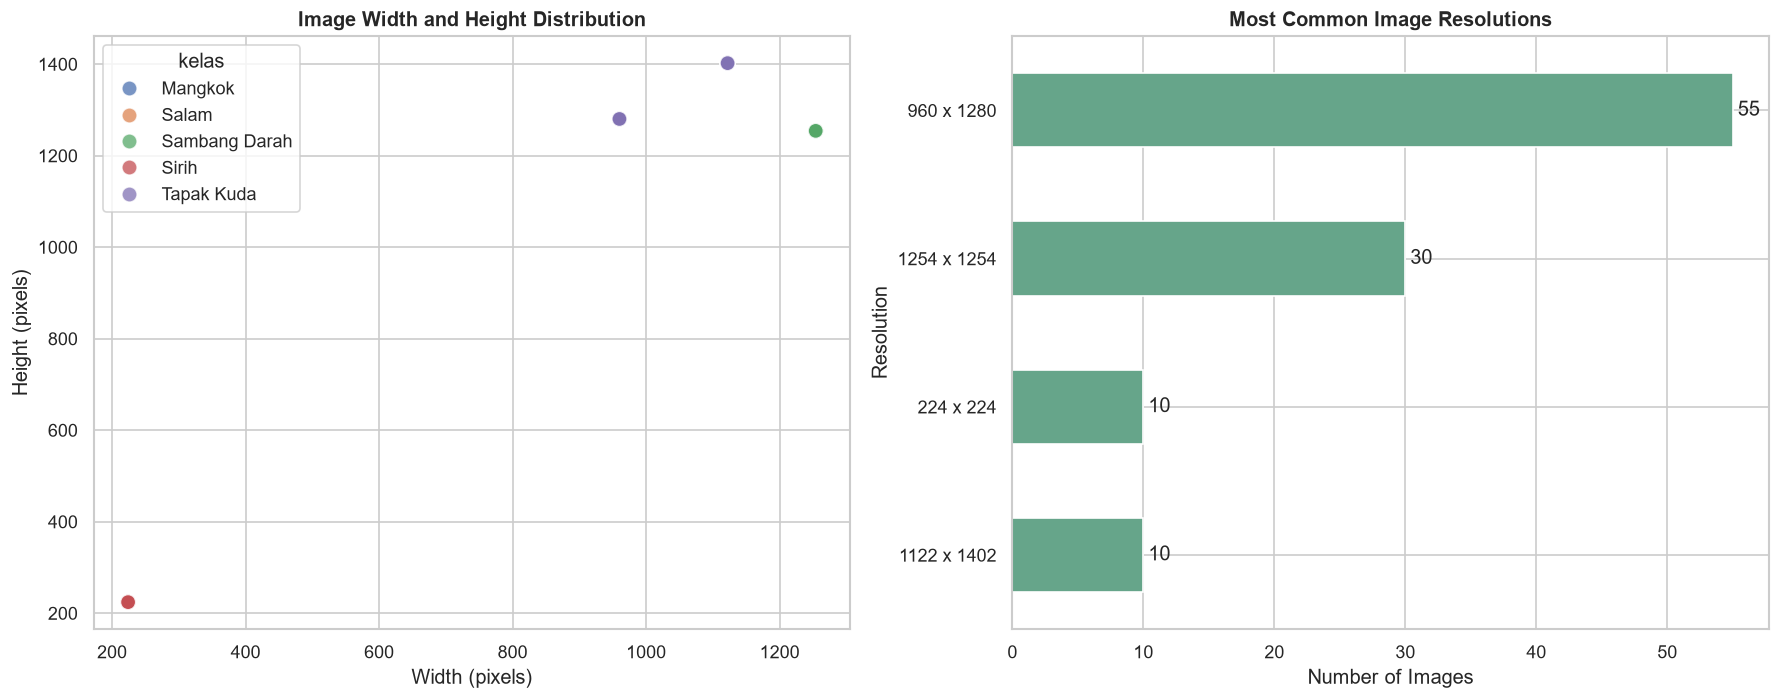


4. ANALYSIS SUMMARY
Minimum width  : 224 pixels
Maximum width  : 1254 pixels
Minimum height : 224 pixels
Maximum height : 1402 pixels

[INFO] Image resolutions are inconsistent.
Image resizing is recommended.

Resolution analysis results saved successfully!


In [9]:
# ==================================================
# IMAGE RESOLUTION ANALYSIS
# ==================================================

print("IMAGE RESOLUTION ANALYSIS")
print("=" * 60)


# 1. Function to extract image dimensions
def get_image_dimensions(image_path):

    try:
        with Image.open(image_path) as img:
            width, height = img.size

        return width, height

    except Exception:
        return np.nan, np.nan


# 2. Extract dimensions from valid images
dimensions = df.apply(
    lambda row: get_image_dimensions(
        row["absolute_image_path"]
    ) if row["image_status"] == "Valid"
    else (np.nan, np.nan),
    axis=1
)

df["image_width"] = dimensions.apply(
    lambda x: x[0]
)

df["image_height"] = dimensions.apply(
    lambda x: x[1]
)

df["aspect_ratio"] = (
    df["image_width"] / df["image_height"]
)

df["resolution"] = df.apply(
    lambda row: (
        f"{int(row['image_width'])} x "
        f"{int(row['image_height'])}"
    )
    if pd.notna(row["image_width"])
    and pd.notna(row["image_height"])
    else None,
    axis=1
)


# 3. Display image dimension samples
print("\n1. IMAGE DIMENSION SAMPLES")

display(
    df[
        [
            "nama_file",
            "kelas",
            "image_width",
            "image_height",
            "aspect_ratio",
            "resolution"
        ]
    ].head(10)
)


# 4. Resolution statistics
print("\n2. IMAGE DIMENSION STATISTICS")

resolution_statistics = df[
    [
        "image_width",
        "image_height",
        "aspect_ratio"
    ]
].describe().round(3)

display(resolution_statistics)


# 5. Resolution distribution
print("\n3. RESOLUTION DISTRIBUTION")

resolution_counts = df[
    "resolution"
].value_counts()

resolution_distribution = pd.DataFrame({
    "Number of Images": resolution_counts,
    "Percentage (%)": (
        resolution_counts /
        resolution_counts.sum() * 100
    ).round(2)
})

display(resolution_distribution)

print(
    f"Unique resolutions: "
    f"{df['resolution'].nunique()}"
)


# 6. Visualize image dimensions
valid_dimensions = df.dropna(
    subset=["image_width", "image_height"]
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6)
)

# Width and height distribution
sns.scatterplot(
    data=valid_dimensions,
    x="image_width",
    y="image_height",
    hue="kelas",
    s=80,
    alpha=0.75,
    ax=axes[0]
)

axes[0].set_title(
    "Image Width and Height Distribution",
    fontweight="bold"
)

axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Height (pixels)")


# Most common resolutions
top_resolutions = resolution_counts.head(10)

top_resolutions.sort_values().plot(
    kind="barh",
    color="#66A58A",
    ax=axes[1]
)

axes[1].set_title(
    "Most Common Image Resolutions",
    fontweight="bold"
)

axes[1].set_xlabel("Number of Images")
axes[1].set_ylabel("Resolution")

for container in axes[1].containers:
    axes[1].bar_label(
        container,
        padding=3
    )

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "03_image_resolution_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 7. Save analysis results
resolution_statistics.to_csv(
    METRICS_DIR / "06_resolution_statistics.csv"
)

resolution_distribution.to_csv(
    METRICS_DIR / "07_resolution_distribution.csv"
)

df[
    [
        "nama_file",
        "kelas",
        "image_width",
        "image_height",
        "aspect_ratio",
        "resolution"
    ]
].to_csv(
    METRICS_DIR / "08_image_dimensions.csv",
    index=False
)


# 8. Analysis summary
print("\n4. ANALYSIS SUMMARY")
print("=" * 60)

print(
    f"Minimum width  : "
    f"{df['image_width'].min():.0f} pixels"
)

print(
    f"Maximum width  : "
    f"{df['image_width'].max():.0f} pixels"
)

print(
    f"Minimum height : "
    f"{df['image_height'].min():.0f} pixels"
)

print(
    f"Maximum height : "
    f"{df['image_height'].max():.0f} pixels"
)

if df["resolution"].nunique() > 1:
    print("\n[INFO] Image resolutions are inconsistent.")
    print("Image resizing is recommended.")

else:
    print("\n[OK] Image resolutions are consistent.")

print("\nResolution analysis results saved successfully!")

DUPLICATE IMAGE DETECTION

1. DUPLICATE DETECTION SUMMARY
Total metadata records : 105
Unique image hashes    : 104
Duplicate groups       : 1
Images in duplicates   : 2
Redundant copies       : 1
Hash failures          : 0

2. DUPLICATE IMAGE DETAILS


,nama_file,kelas,tampilan_daun,image_path,image_hash,duplicate_remove_candidate
27,daun salam 7.jpeg,Salam,belakang,dataset/daun_salam/foto belakang/daun salam 7....,83f7ce36bf9f7b4e03f0e561be6da4c21be7cc8c6a340d...,False
28,daun salam 8.jpeg,Salam,belakang,dataset/daun_salam/foto belakang/daun salam 8....,83f7ce36bf9f7b4e03f0e561be6da4c21be7cc8c6a340d...,True


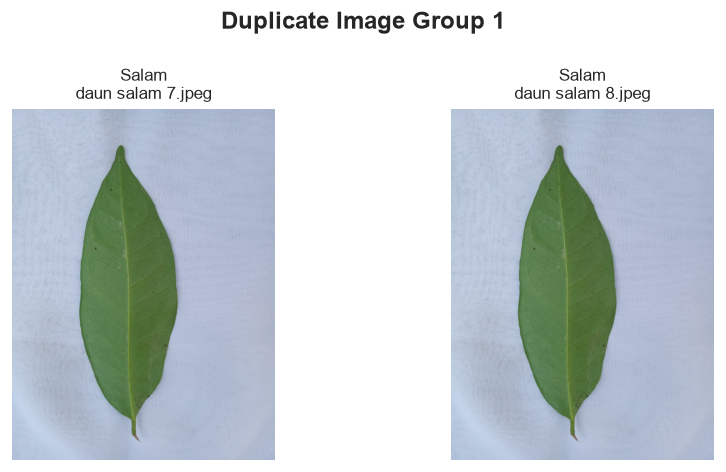


3. DETECTION SUMMARY
[WARNING] Found 1 redundant image copies.
Review duplicate groups before dataset cleaning.

Original dataset has not been modified.


In [10]:
# ==================================================
# DUPLICATE IMAGE DETECTION
# ==================================================

print("DUPLICATE IMAGE DETECTION")
print("=" * 60)


# 1. Function to calculate SHA-256 image hash
def calculate_image_hash(image_path):

    try:
        sha256_hash = hashlib.sha256()

        with open(image_path, "rb") as file:

            for block in iter(
                lambda: file.read(65536),
                b""
            ):
                sha256_hash.update(block)

        return sha256_hash.hexdigest()

    except Exception:
        return None


# 2. Calculate hash for valid images
df["image_hash"] = df.apply(
    lambda row: calculate_image_hash(
        row["absolute_image_path"]
    )
    if row["image_status"] == "Valid"
    else None,
    axis=1
)


# 3. Identify all members of duplicate groups
valid_hash_mask = df["image_hash"].notna()

df["is_duplicate"] = (
    valid_hash_mask
    & df["image_hash"].duplicated(keep=False)
)


# 4. Identify redundant copies
df["duplicate_remove_candidate"] = (
    valid_hash_mask
    & df["image_hash"].duplicated(keep="first")
)


# 5. Extract duplicate images
duplicate_images = df[
    df["is_duplicate"]
].sort_values("image_hash")

duplicate_groups = duplicate_images[
    "image_hash"
].nunique()

redundant_images = int(
    df["duplicate_remove_candidate"].sum()
)

unique_images = df[
    "image_hash"
].nunique()

hash_failures = int(
    (
        df["image_status"].eq("Valid")
        & df["image_hash"].isna()
    ).sum()
)


# 6. Display duplicate statistics
print("\n1. DUPLICATE DETECTION SUMMARY")

print(f"Total metadata records : {len(df)}")
print(f"Unique image hashes    : {unique_images}")
print(f"Duplicate groups       : {duplicate_groups}")
print(f"Images in duplicates   : {len(duplicate_images)}")
print(f"Redundant copies       : {redundant_images}")
print(f"Hash failures          : {hash_failures}")


# 7. Display duplicate image details
print("\n2. DUPLICATE IMAGE DETAILS")

if duplicate_images.empty:

    print("[OK] No exact duplicate images detected.")

else:

    display(
        duplicate_images[
            [
                "nama_file",
                "kelas",
                "tampilan_daun",
                "image_path",
                "image_hash",
                "duplicate_remove_candidate"
            ]
        ]
    )


# 8. Visualize duplicate image groups
if not duplicate_images.empty:

    for group_number, (image_hash, group) in enumerate(
        duplicate_images.groupby("image_hash"),
        start=1
    ):

        group = group.reset_index(drop=True)

        fig, axes = plt.subplots(
            1,
            len(group),
            figsize=(4 * len(group), 4),
            squeeze=False
        )

        for ax, (_, row) in zip(
            axes.ravel(),
            group.iterrows()
        ):

            with Image.open(
                row["absolute_image_path"]
            ) as img:

                ax.imshow(img.convert("RGB"))

            ax.set_title(
                f"{row['kelas']}\n"
                f"{row['nama_file']}",
                fontsize=10
            )

            ax.axis("off")

        fig.suptitle(
            f"Duplicate Image Group {group_number}",
            fontweight="bold"
        )

        plt.tight_layout()

        plt.savefig(
            FIGURES_DIR /
            f"04_duplicate_group_{group_number}.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()


# 9. Save duplicate detection results
duplicate_images[
    [
        "nama_file",
        "kelas",
        "tampilan_daun",
        "image_path",
        "image_hash",
        "duplicate_remove_candidate"
    ]
].to_csv(
    METRICS_DIR / "09_duplicate_images.csv",
    index=False
)


# 10. Final summary
print("\n3. DETECTION SUMMARY")
print("=" * 60)

if redundant_images > 0:

    print(
        f"[WARNING] Found {redundant_images} "
        "redundant image copies."
    )

    print(
        "Review duplicate groups before "
        "dataset cleaning."
    )

elif hash_failures > 0:

    print("[WARNING] Some image hashes failed.")

else:

    print("[PASS] No exact duplicate files found.")

print("\nOriginal dataset has not been modified.")

SAMPLE IMAGE VISUALIZATION


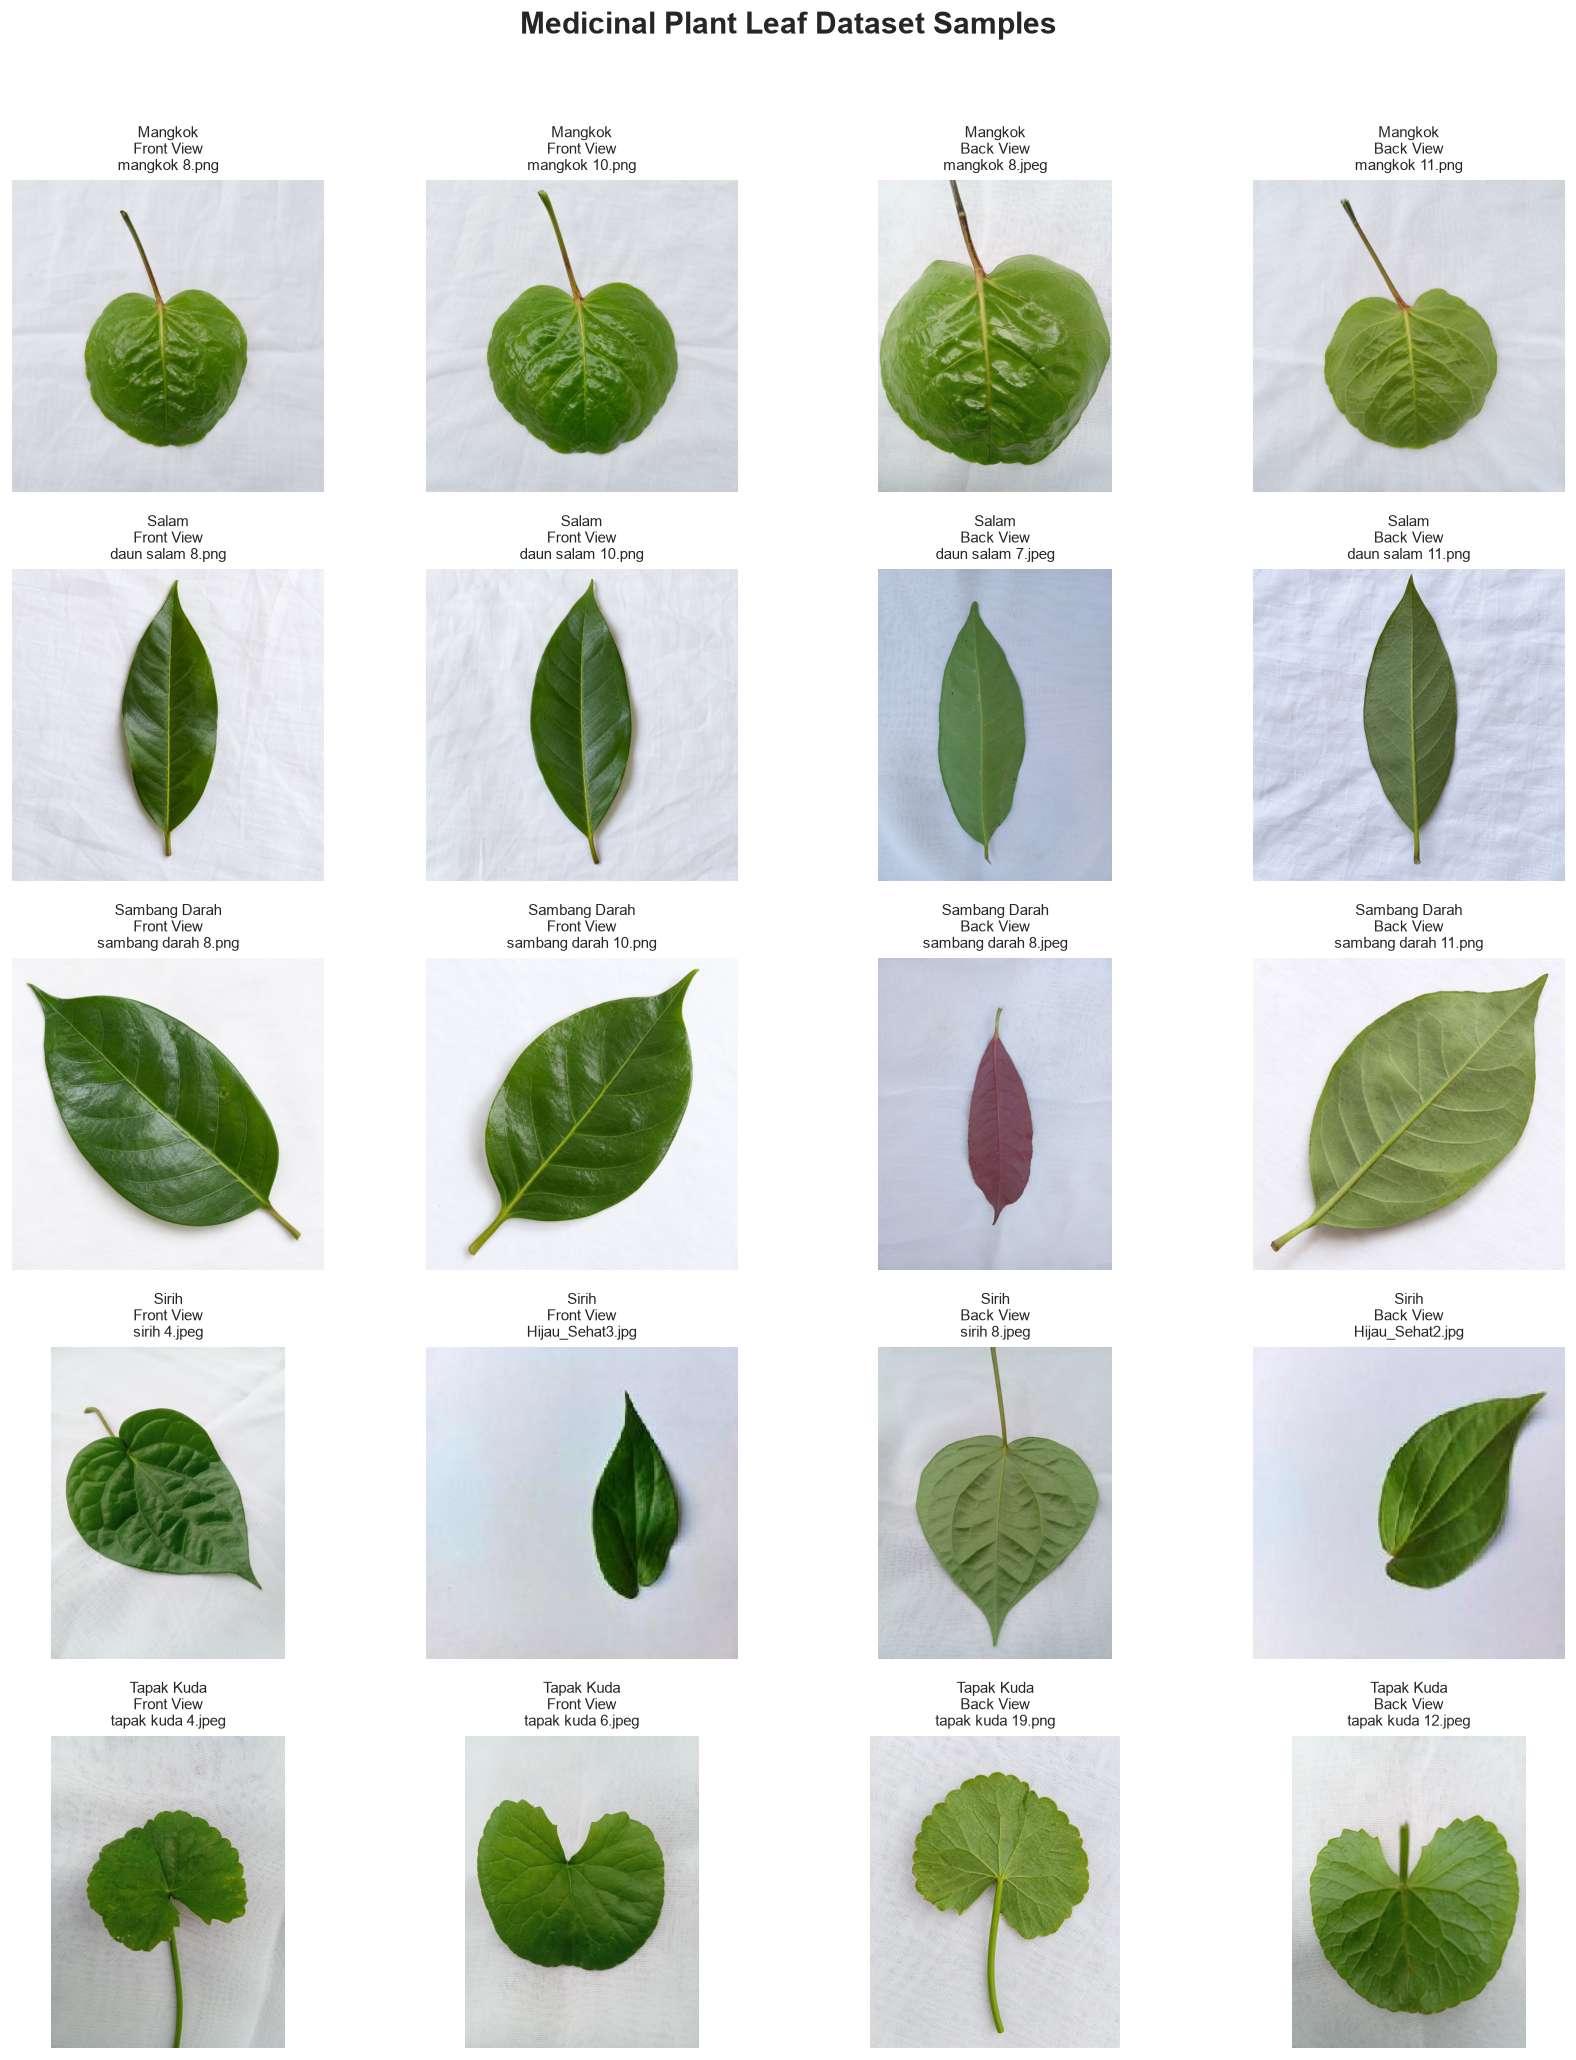


VISUALIZATION SUMMARY
Plant classes    : 5
Leaf views       : 2
Samples per view : 2
Maximum displayed samples : 20

Dataset samples saved successfully!


In [11]:
# ==================================================
# SAMPLE IMAGE VISUALIZATION
# ==================================================

from PIL import ImageOps

print("SAMPLE IMAGE VISUALIZATION")
print("=" * 60)


# 1. Select valid and non-redundant images
visualization_df = df[
    df["image_status"].eq("Valid")
    & ~df["duplicate_remove_candidate"]
].copy()

visualization_df["view_normalized"] = leaf_views


# 2. Define classes and leaf views
plant_classes = sorted(
    visualization_df["kelas"].dropna().unique()
)

views = ["depan", "belakang"]

view_titles = {
    "depan": "Front View",
    "belakang": "Back View"
}

samples_per_view = 2

n_rows = len(plant_classes)
n_cols = len(views) * samples_per_view


# 3. Create visualization figure
fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(14, 3.5 * n_rows),
    squeeze=False
)


# 4. Display image samples
for row_index, plant_class in enumerate(
    plant_classes
):

    for view_index, view in enumerate(views):

        subset = visualization_df[
            visualization_df["kelas"].eq(plant_class)
            & visualization_df[
                "view_normalized"
            ].eq(view)
        ]

        n_samples = min(
            samples_per_view,
            len(subset)
        )

        if n_samples > 0:

            samples = subset.sample(
                n=n_samples,
                random_state=42
            ).reset_index(drop=True)

        else:

            samples = subset

        for sample_index in range(
            samples_per_view
        ):

            col_index = (
                view_index * samples_per_view
                + sample_index
            )

            ax = axes[row_index, col_index]

            if sample_index < len(samples):

                row = samples.iloc[sample_index]

                with Image.open(
                    row["absolute_image_path"]
                ) as img:

                    image = ImageOps.exif_transpose(
                        img
                    ).convert("RGB")

                    ax.imshow(image)

                ax.set_title(
                    f"{plant_class}\n"
                    f"{view_titles[view]}\n"
                    f"{row['nama_file']}",
                    fontsize=9
                )

            else:

                ax.text(
                    0.5,
                    0.5,
                    "No image available",
                    ha="center",
                    va="center"
                )

            ax.axis("off")


# 5. Add figure title
fig.suptitle(
    "Medicinal Plant Leaf Dataset Samples",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)


# 6. Save sample visualization
plt.savefig(
    FIGURES_DIR / "05_dataset_samples.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 7. Visualization summary
print("\nVISUALIZATION SUMMARY")
print("=" * 60)

print(f"Plant classes    : {len(plant_classes)}")
print(f"Leaf views       : {len(views)}")
print(f"Samples per view : {samples_per_view}")

print(
    "Maximum displayed samples : "
    f"{n_rows * n_cols}"
)

print("\nDataset samples saved successfully!")

TEXT DESCRIPTION ANALYSIS

1. TEXT DESCRIPTION STATISTICS


,description_char_count,description_word_count
count,105.00,105.00
mean,157.08,21.03
std,11.14,1.23
min,127.00,18.00
25%,150.00,20.00
50%,156.00,21.00
75%,164.00,22.00
max,182.00,24.00


Total descriptions     : 105
Empty descriptions     : 0
Unique descriptions    : 95
Repeated descriptions  : 19
Containing class names : 0

2. DESCRIPTION LENGTH PER CLASS


,count,mean,min,max,std
kelas,,,,,
Mangkok,20,21.65,20,23,1.04
Salam,20,20.65,19,23,0.93
Sambang Darah,20,20.55,18,23,1.36
Sirih,20,21.40,18,24,1.43
Tapak Kuda,25,20.92,20,23,1.08



3. MOST FREQUENT WORDS


,Word,Frequency
0,daun,122
1,berbentuk,115
2,permukaan,111
3,berwarna,105
4,tepi,105
5,ujung,105
6,hijau,101
7,membulat,83
8,urat,73
9,halus,72


Total analyzed tokens : 1836
Vocabulary size       : 63


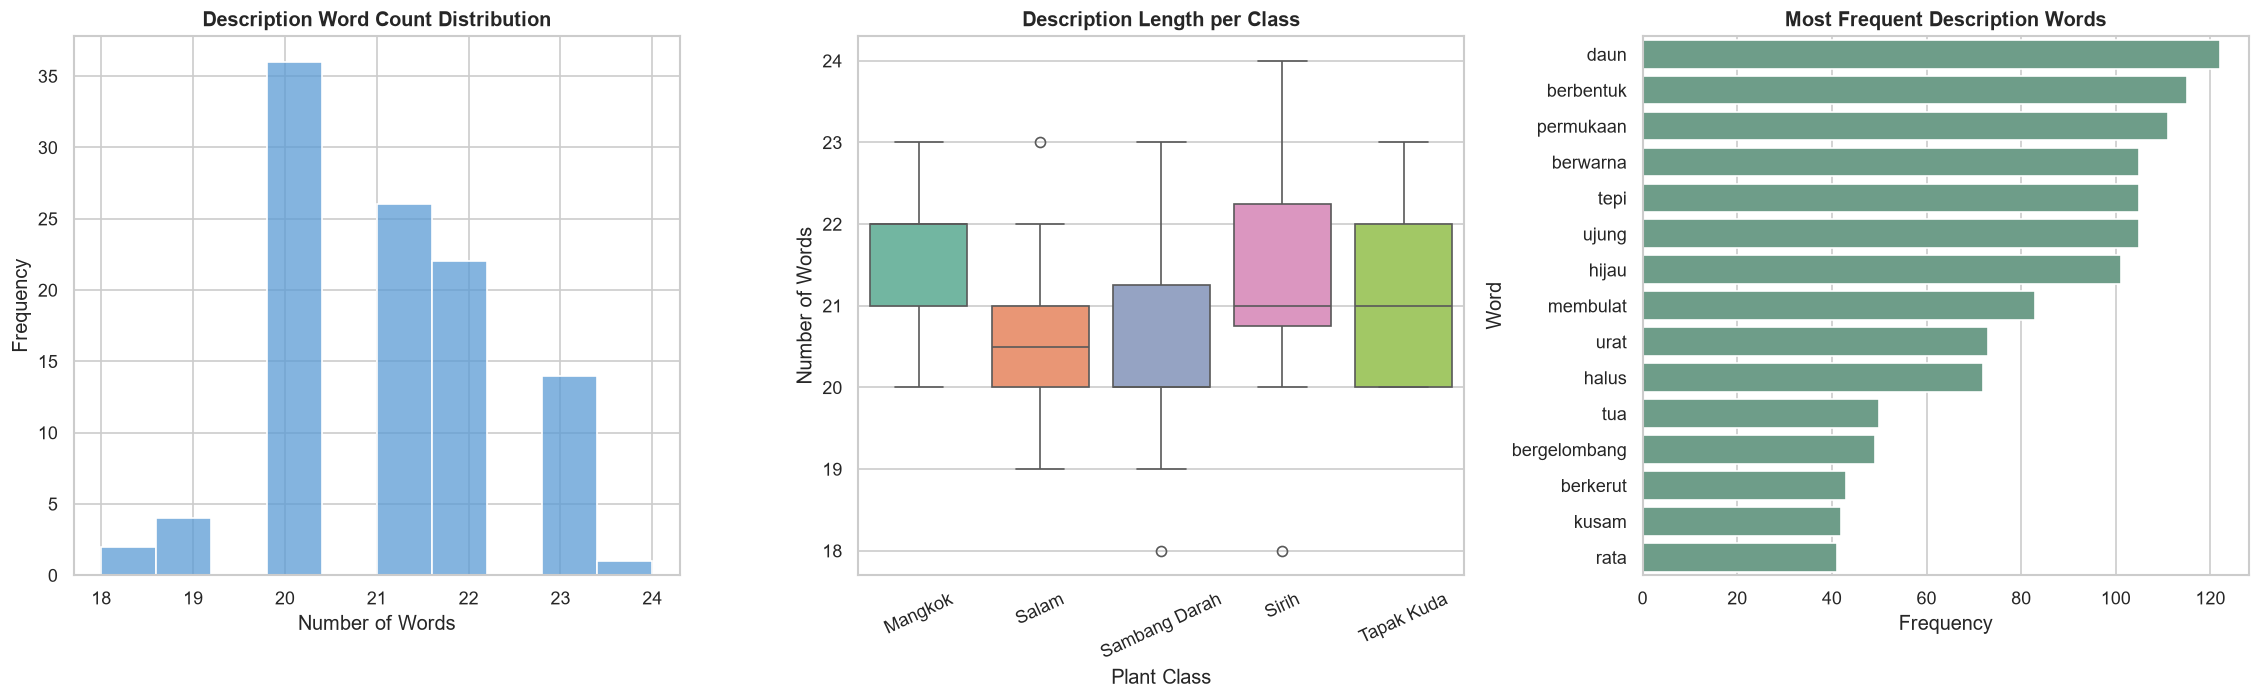


4. CLASS NAME LEAKAGE INSPECTION
[OK] No explicit class names detected in descriptions.

5. TEXT ANALYSIS SUMMARY
[OK] All descriptions are available.
Average description length: 21.03 words

Text analysis results saved successfully!


In [12]:
# ==================================================
# TEXT DESCRIPTION ANALYSIS
# ==================================================

import re

print("TEXT DESCRIPTION ANALYSIS")
print("=" * 60)


# 1. Prepare textual descriptions
text_descriptions = (
    df["deskripsi_lengkap"]
    .fillna("")
    .astype(str)
    .str.strip()
)


# 2. Calculate description length
df["description_char_count"] = (
    text_descriptions.str.len()
)

df["description_word_count"] = (
    text_descriptions.apply(
        lambda text: len(
            re.findall(r"\b\w+\b", text)
        )
    )
)


# 3. Detect empty descriptions
df["is_empty_description"] = (
    text_descriptions.eq("")
)

empty_descriptions = int(
    df["is_empty_description"].sum()
)


# 4. Detect identical descriptions
normalized_descriptions = (
    text_descriptions
    .str.lower()
    .str.replace(
        r"\s+",
        " ",
        regex=True
    )
)

df["is_duplicate_description"] = (
    ~df["is_empty_description"]
    & normalized_descriptions.duplicated(
        keep=False
    )
)


# 5. Detect explicit class names in descriptions
class_patterns = {
    plant_class: re.compile(
        r"\b"
        + re.escape(str(plant_class))
        + r"\b",
        flags=re.IGNORECASE
    )
    for plant_class in expected_classes
}

df["contains_class_name"] = df.apply(
    lambda row: bool(
        class_patterns[row["kelas"]].search(
            str(row["deskripsi_lengkap"])
        )
    )
    if row["kelas"] in class_patterns
    else False,
    axis=1
)


# 6. Display text statistics
print("\n1. TEXT DESCRIPTION STATISTICS")

text_statistics = df[
    [
        "description_char_count",
        "description_word_count"
    ]
].describe().round(2)

display(text_statistics)

print(f"Total descriptions     : {len(df)}")
print(f"Empty descriptions     : {empty_descriptions}")

print(
    f"Unique descriptions    : "
    f"{normalized_descriptions[normalized_descriptions.ne('')].nunique()}"
)

print(
    f"Repeated descriptions  : "
    f"{df['is_duplicate_description'].sum()}"
)

print(
    f"Containing class names : "
    f"{df['contains_class_name'].sum()}"
)


# 7. Analyze description length per class
print("\n2. DESCRIPTION LENGTH PER CLASS")

class_text_statistics = df.groupby(
    "kelas"
)["description_word_count"].agg(
    ["count", "mean", "min", "max", "std"]
).round(2)

display(class_text_statistics)


# 8. Define basic stopwords for EDA
stopwords_eda = {
    "dan",
    "yang",
    "dengan",
    "pada",
    "di",
    "ke",
    "dari",
    "terlihat",
    "memiliki",
    "tampak",
    "bagian",
    "secara",
    "ini",
    "terdapat"
}


# 9. Tokenize descriptions
all_tokens = []

for description in text_descriptions:

    tokens = re.findall(
        r"\b[a-zA-Z]+\b",
        description.lower()
    )

    tokens = [
        token
        for token in tokens
        if token not in stopwords_eda
    ]

    all_tokens.extend(tokens)


# 10. Count word frequencies
word_counter = Counter(all_tokens)

word_frequency = pd.DataFrame(
    word_counter.most_common(20),
    columns=["Word", "Frequency"]
)

print("\n3. MOST FREQUENT WORDS")

display(word_frequency)

print(
    f"Total analyzed tokens : {len(all_tokens)}"
)

print(
    f"Vocabulary size       : {len(word_counter)}"
)


# 11. Visualize textual characteristics
fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 6)
)

# Word count distribution
sns.histplot(
    data=df,
    x="description_word_count",
    bins=10,
    kde=False,
    color="#5B9BD5",
    ax=axes[0]
)

axes[0].set_title(
    "Description Word Count Distribution",
    fontweight="bold"
)

axes[0].set_xlabel("Number of Words")
axes[0].set_ylabel("Frequency")


# Word count per class
sns.boxplot(
    data=df,
    x="kelas",
    y="description_word_count",
    hue="kelas",
    palette="Set2",
    legend=False,
    ax=axes[1]
)

axes[1].set_title(
    "Description Length per Class",
    fontweight="bold"
)

axes[1].set_xlabel("Plant Class")
axes[1].set_ylabel("Number of Words")
axes[1].tick_params(axis="x", rotation=25)


# Most frequent words
if not word_frequency.empty:

    sns.barplot(
        data=word_frequency.head(15),
        x="Frequency",
        y="Word",
        color="#66A58A",
        ax=axes[2]
    )

axes[2].set_title(
    "Most Frequent Description Words",
    fontweight="bold"
)

axes[2].set_xlabel("Frequency")
axes[2].set_ylabel("Word")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "06_text_description_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 12. Display descriptions containing class names
print("\n4. CLASS NAME LEAKAGE INSPECTION")

class_name_descriptions = df[
    df["contains_class_name"]
]

if class_name_descriptions.empty:

    print(
        "[OK] No explicit class names "
        "detected in descriptions."
    )

else:

    display(
        class_name_descriptions[
            [
                "nama_file",
                "kelas",
                "deskripsi_lengkap"
            ]
        ].head(10)
    )


# 13. Save textual analysis results
text_statistics.to_csv(
    METRICS_DIR / "10_text_statistics.csv"
)

class_text_statistics.to_csv(
    METRICS_DIR / "11_class_text_statistics.csv"
)

word_frequency.to_csv(
    METRICS_DIR / "12_word_frequency.csv",
    index=False
)

df[
    [
        "nama_file",
        "kelas",
        "description_char_count",
        "description_word_count",
        "is_empty_description",
        "is_duplicate_description",
        "contains_class_name"
    ]
].to_csv(
    METRICS_DIR / "13_text_quality_details.csv",
    index=False
)


# 14. Text analysis summary
print("\n5. TEXT ANALYSIS SUMMARY")
print("=" * 60)

if empty_descriptions == 0:

    print("[OK] All descriptions are available.")

else:

    print(
        f"[WARNING] Found {empty_descriptions} "
        "empty descriptions."
    )

print(
    "Average description length: "
    f"{df['description_word_count'].mean():.2f} words"
)

if df["contains_class_name"].any():

    print(
        "[REVIEW] Explicit class names "
        "require inspection before retrieval evaluation."
    )

print("\nText analysis results saved successfully!")

DATASET QUALITY ASSESSMENT

1. DATASET QUALITY INDICATORS


,Quality Indicator,Count,Percentage (%)
0,Total metadata records,105,100.00
1,Valid image files,105,100.00
2,Missing image files,0,0.00
3,Corrupted image files,0,0.00
4,Redundant image copies,1,0.95
5,Hash failures,0,0.00
6,Missing essential metadata,0,0.00
7,Incomplete morphology attributes,0,0.00
8,Invalid class labels,0,0.00
9,Invalid leaf view labels,0,0.00



2. OVERALL QUALITY STATUS


,Number of Records,Percentage (%)
quality_status,,
Ready,57,54.29
Needs Review,47,44.76
Exclude Candidate,1,0.95



3. RECORDS REQUIRING REVIEW


,nama_file,kelas,tampilan_daun,image_status,is_duplicate,contains_class_name,is_low_resolution,has_incomplete_morphology,catatan_verifikasi,quality_status
0,mangkok 10.jpeg,Mangkok,belakang,Valid,False,False,False,False,Tampilan mengikuti folder; verifikasi sisi dau...,Needs Review
6,mangkok 6.jpeg,Mangkok,belakang,Valid,False,False,False,False,Tampilan mengikuti folder; verifikasi sisi dau...,Needs Review
7,mangkok 7.jpeg,Mangkok,belakang,Valid,False,False,False,False,Detail visual terbatas; periksa foto resolusi ...,Needs Review
8,mangkok 8.jpeg,Mangkok,belakang,Valid,False,False,False,False,Tampilan mengikuti folder; verifikasi sisi dau...,Needs Review
9,mangkok 9.jpeg,Mangkok,belakang,Valid,False,False,False,False,Tampilan mengikuti folder; verifikasi sisi dau...,Needs Review
26,daun salam 6.jpeg,Salam,belakang,Valid,False,False,False,False,Detail visual terbatas; periksa foto resolusi ...,Needs Review
27,daun salam 7.jpeg,Salam,belakang,Valid,True,False,False,False,NaN,Needs Review
28,daun salam 8.jpeg,Salam,belakang,Valid,True,False,False,False,Duplikat identik: dataset/daun_salam/foto bela...,Exclude Candidate
29,daun salam 9.jpeg,Salam,belakang,Valid,False,False,False,False,Detail visual terbatas; periksa foto resolusi ...,Needs Review
32,daun salam 2.jpeg,Salam,depan,Valid,False,False,False,False,Detail visual terbatas; periksa foto resolusi ...,Needs Review


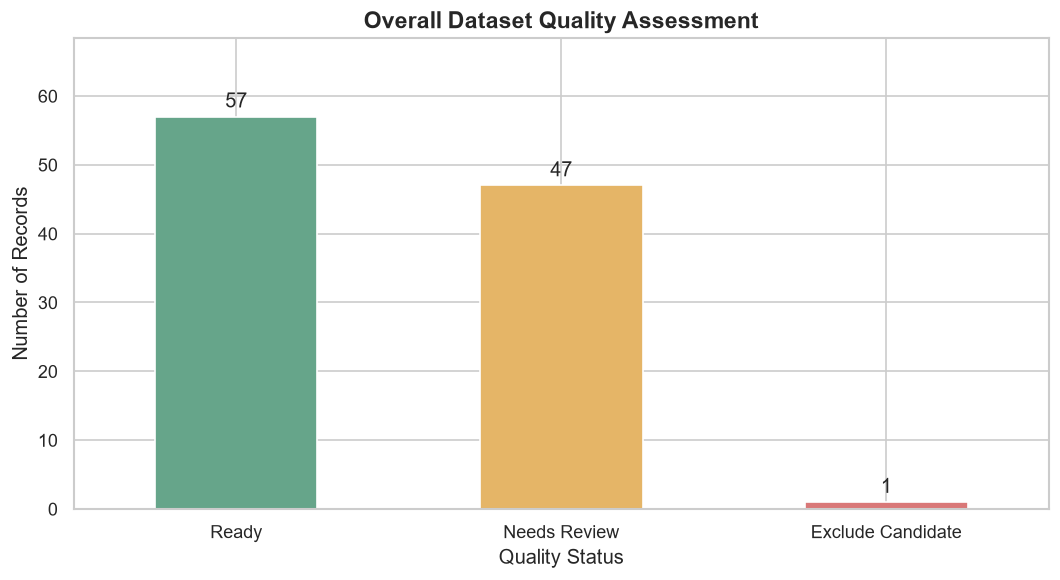


4. QUALITY ASSESSMENT SUMMARY
Ready records       : 57
Needs review        : 47
Exclude candidates  : 1

Original dataset has not been modified.
Dataset quality assessment saved successfully!


In [13]:
# ==================================================
# DATASET QUALITY ASSESSMENT
# ==================================================

print("DATASET QUALITY ASSESSMENT")
print("=" * 60)


# 1. Identify missing essential metadata
essential_columns = [
    "nama_file",
    "image_path",
    "kelas",
    "tampilan_daun",
    "deskripsi_lengkap"
]

df["has_missing_metadata"] = df[
    essential_columns
].apply(
    lambda column: (
        column.isna()
        | column.fillna("").astype(str)
        .str.strip().eq("")
    )
).any(axis=1)


# 2. Identify incomplete morphological attributes
morphology_columns = [
    "warna",
    "bentuk",
    "tepi",
    "ujung",
    "tekstur"
]

df["has_incomplete_morphology"] = df[
    morphology_columns
].apply(
    lambda column: (
        column.isna()
        | column.fillna("").astype(str)
        .str.strip().eq("")
    )
).any(axis=1)


# 3. Validate class and view labels
df["has_invalid_class"] = (
    ~df["kelas"].isin(expected_classes)
)

df["has_invalid_view"] = (
    ~leaf_views.isin(["depan", "belakang"])
)


# 4. Check manual verification notes
verification_notes = (
    df["catatan_verifikasi"]
    .fillna("")
    .astype(str)
    .str.strip()
)

df["requires_manual_verification"] = (
    ~verification_notes.str.lower().isin(
        ["", "-", "none", "nan", "tidak ada", "ok"]
    )
)


# 5. Identify low-resolution images
# Initial review threshold, not an exclusion rule
MIN_REVIEW_DIMENSION = 128

df["is_low_resolution"] = (
    df["image_width"].lt(MIN_REVIEW_DIMENSION)
    | df["image_height"].lt(MIN_REVIEW_DIMENSION)
)


# 6. Identify hash failures
df["has_hash_failure"] = (
    df["image_status"].eq("Valid")
    & df["image_hash"].isna()
)


# 7. Identify exclusion candidates
df["exclude_candidate"] = (
    df["image_status"].ne("Valid")
    | df["has_missing_metadata"]
    | df["has_invalid_class"]
    | df["has_invalid_view"]
    | df["duplicate_remove_candidate"]
)


# 8. Identify manual review candidates
df["review_candidate"] = (
    df["requires_manual_verification"]
    | df["is_low_resolution"]
    | df["contains_class_name"]
    | df["is_duplicate"]
    | df["has_incomplete_morphology"]
    | df["has_hash_failure"]
)


# 9. Assign dataset quality status
df["quality_status"] = np.select(
    [
        df["exclude_candidate"],
        df["review_candidate"]
    ],
    [
        "Exclude Candidate",
        "Needs Review"
    ],
    default="Ready"
)


# 10. Create quality assessment table
quality_assessment = pd.DataFrame({
    "Quality Indicator": [
        "Total metadata records",
        "Valid image files",
        "Missing image files",
        "Corrupted image files",
        "Redundant image copies",
        "Hash failures",
        "Missing essential metadata",
        "Incomplete morphology attributes",
        "Invalid class labels",
        "Invalid leaf view labels",
        "Empty descriptions",
        "Descriptions containing class names",
        "Repeated descriptions",
        "Low-resolution images",
        "Manual verification notes"
    ],

    "Count": [
        len(df),
        df["image_status"].eq("Valid").sum(),
        df["image_status"].eq("Missing").sum(),
        df["image_status"].eq("Corrupted").sum(),
        df["duplicate_remove_candidate"].sum(),
        df["has_hash_failure"].sum(),
        df["has_missing_metadata"].sum(),
        df["has_incomplete_morphology"].sum(),
        df["has_invalid_class"].sum(),
        df["has_invalid_view"].sum(),
        df["is_empty_description"].sum(),
        df["contains_class_name"].sum(),
        df["is_duplicate_description"].sum(),
        df["is_low_resolution"].sum(),
        df["requires_manual_verification"].sum()
    ]
})

quality_assessment["Percentage (%)"] = (
    quality_assessment["Count"]
    / len(df) * 100
).round(2)

print("\n1. DATASET QUALITY INDICATORS")

display(quality_assessment)


# 11. Summarize overall quality status
quality_status_counts = (
    df["quality_status"]
    .value_counts()
    .reindex(
        [
            "Ready",
            "Needs Review",
            "Exclude Candidate"
        ],
        fill_value=0
    )
)

quality_status_summary = pd.DataFrame({
    "Number of Records": quality_status_counts,

    "Percentage (%)": (
        quality_status_counts
        / len(df) * 100
    ).round(2)
})

print("\n2. OVERALL QUALITY STATUS")

display(quality_status_summary)


# 12. Display records requiring review
print("\n3. RECORDS REQUIRING REVIEW")

review_columns = [
    "nama_file",
    "kelas",
    "tampilan_daun",
    "image_status",
    "is_duplicate",
    "contains_class_name",
    "is_low_resolution",
    "has_incomplete_morphology",
    "catatan_verifikasi",
    "quality_status"
]

problem_records = df[
    df["quality_status"].ne("Ready")
]

if problem_records.empty:

    print("[OK] No quality issues detected.")

else:

    display(
        problem_records[review_columns]
    )


# 13. Visualize quality assessment
fig, ax = plt.subplots(
    figsize=(9, 5)
)

quality_status_counts.plot(
    kind="bar",
    color=[
        "#66A58A",
        "#E5B567",
        "#D97878"
    ],
    rot=0,
    ax=ax
)

ax.set_title(
    "Overall Dataset Quality Assessment",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Quality Status")
ax.set_ylabel("Number of Records")

ax.set_ylim(
    0,
    max(quality_status_counts.max(), 1) * 1.2
)

for container in ax.containers:

    ax.bar_label(
        container,
        padding=3
    )

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "07_dataset_quality_assessment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 14. Save quality assessment results
quality_assessment.to_csv(
    METRICS_DIR / "14_dataset_quality_assessment.csv",
    index=False
)

quality_status_summary.to_csv(
    METRICS_DIR / "15_quality_status_summary.csv"
)

problem_records[review_columns].to_csv(
    METRICS_DIR / "16_records_requiring_review.csv",
    index=False
)

df.to_csv(
    METRICS_DIR / "17_full_dataset_audit.csv",
    index=False,
    encoding="utf-8-sig"
)


# 15. Final quality summary
print("\n4. QUALITY ASSESSMENT SUMMARY")
print("=" * 60)

print(
    f"Ready records       : "
    f"{quality_status_counts['Ready']}"
)

print(
    f"Needs review        : "
    f"{quality_status_counts['Needs Review']}"
)

print(
    f"Exclude candidates  : "
    f"{quality_status_counts['Exclude Candidate']}"
)

print("\nOriginal dataset has not been modified.")
print("Dataset quality assessment saved successfully!")

In [14]:
# ==================================================
# EDA CONCLUSION
# ==================================================

print("=" * 65)
print("FINAL EXPLORATORY DATA ANALYSIS REPORT")
print("=" * 65)


# 1. Dataset overview
total_records = len(df)

total_classes = df["kelas"].nunique()

total_valid_images = int(
    df["image_status"].eq("Valid").sum()
)

total_corrupted_images = int(
    df["image_status"].eq("Corrupted").sum()
)

total_missing_images = int(
    df["image_status"].eq("Missing").sum()
)

total_unique_images = df["image_hash"].nunique()

total_redundant_images = int(
    df["duplicate_remove_candidate"].sum()
)

total_descriptions = int(
    (~df["is_empty_description"]).sum()
)


# 2. Quality statistics
ready_records = int(
    df["quality_status"].eq("Ready").sum()
)

review_records = int(
    df["quality_status"].eq("Needs Review").sum()
)

exclude_records = int(
    df["quality_status"].eq(
        "Exclude Candidate"
    ).sum()
)


# 3. Create final summary
eda_summary = pd.DataFrame({
    "Indicator": [
        "Total metadata records",
        "Total plant classes",
        "Valid images",
        "Corrupted images",
        "Missing images",
        "Unique image hashes",
        "Redundant image copies",
        "Available descriptions",
        "Empty descriptions",
        "Front-view images",
        "Back-view images",
        "Unique image resolutions",
        "Class imbalance ratio",
        "Average description words",
        "Ready records",
        "Records requiring review",
        "Exclusion candidates"
    ],

    "Result": [
        total_records,
        total_classes,
        total_valid_images,
        total_corrupted_images,
        total_missing_images,
        total_unique_images,
        total_redundant_images,
        total_descriptions,
        int(df["is_empty_description"].sum()),
        int(leaf_views.eq("depan").sum()),
        int(leaf_views.eq("belakang").sum()),
        df["resolution"].nunique(),
        round(imbalance_ratio, 2),
        round(
            df["description_word_count"].mean(),
            2
        ),
        ready_records,
        review_records,
        exclude_records
    ]
})

print("\n1. FINAL DATASET SUMMARY")

display(eda_summary)


# 4. Dataset conclusions
print("\n2. DATASET CONCLUSIONS")
print("-" * 65)

print(
    f"The dataset contains {total_records} "
    f"metadata records across {total_classes} "
    "medicinal plant classes."
)

print(
    f"A total of {total_valid_images} "
    "image files are valid and readable."
)

print(
    f"The dataset contains {total_descriptions} "
    "available textual descriptions."
)

print(
    f"The class imbalance ratio is "
    f"{imbalance_ratio:.2f}."
)

if df["resolution"].nunique() > 1:

    print(
        "Image resolutions vary, requiring "
        "consistent image resizing."
    )

if total_redundant_images > 0:

    print(
        f"{total_redundant_images} redundant "
        "image copies were identified."
    )

if df["contains_class_name"].any():

    print(
        "Some descriptions contain explicit "
        "class names and require inspection."
    )

if review_records > 0:

    print(
        f"{review_records} records require "
        "manual quality verification."
    )


# 5. Preprocessing recommendations
recommendations = [
    "Verify image labels and morphological descriptions.",
    "Review exact duplicate groups before exclusion.",
    "Inspect near-duplicate and related leaf photographs.",
    "Preserve the original image dataset.",
    "Resize images while maintaining aspect ratio.",
    "Segment leaf objects from the background.",
    "Apply denoising only when necessary.",
    "Convert images into appropriate color spaces.",
    "Normalize and clean textual descriptions.",
    "Review explicit class names before TF-IDF.",
    "Identify front/back images of the same physical leaf.",
    "Separate reference, validation, and test queries.",
    "Prevent data leakage during retrieval evaluation."
]

print("\n3. PREPROCESSING RECOMMENDATIONS")
print("-" * 65)

for index, recommendation in enumerate(
    recommendations,
    start=1
):

    print(f"{index}. {recommendation}")


# 6. Determine dataset readiness
print("\n4. DATASET READINESS")
print("-" * 65)

if exclude_records == 0 and review_records == 0:

    readiness_status = (
        "PASSED AUTOMATED EDA CHECKS"
    )

elif exclude_records == 0:

    readiness_status = (
        "REQUIRES MANUAL REVIEW"
    )

else:

    readiness_status = (
        "REQUIRES DATA CLEANING AND REVIEW"
    )

print(f"Status: {readiness_status}")


# 7. Save final EDA summary
eda_summary.to_csv(
    METRICS_DIR / "18_final_eda_summary.csv",
    index=False
)


# 8. Save preliminary dataset candidates
candidate_df = df[
    ~df["exclude_candidate"]
].copy()

candidate_df["image_path"] = candidate_df[
    "absolute_image_path"
].apply(
    lambda path: (
        path.resolve()
        .relative_to(PROJECT_ROOT.resolve())
        .as_posix()
    )
)

candidate_columns = required_columns + [
    "image_width",
    "image_height",
    "resolution",
    "image_hash",
    "quality_status",
    "review_candidate"
]

candidate_df[candidate_columns].to_csv(
    PROCESSED_DIR /
    "metadata_preprocessing_candidates.csv",
    index=False,
    encoding="utf-8-sig"
)


# 9. Save textual EDA report
report_path = RESULTS_DIR / "eda_report.txt"

with open(
    report_path,
    "w",
    encoding="utf-8"
) as report:

    report.write(
        "MULTIMODAL MEDICINAL PLANT LEAF RETRIEVAL\n"
    )

    report.write(
        "EXPLORATORY DATA ANALYSIS REPORT\n"
    )

    report.write("=" * 65 + "\n\n")

    report.write(
        eda_summary.to_string(index=False)
    )

    report.write(
        "\n\nPREPROCESSING RECOMMENDATIONS\n"
    )

    for index, recommendation in enumerate(
        recommendations,
        start=1
    ):

        report.write(
            f"{index}. {recommendation}\n"
        )

    report.write(
        f"\nDataset readiness: "
        f"{readiness_status}\n"
    )

    report.write(
        f"Preliminary candidate records: "
        f"{len(candidate_df)}\n"
    )

    report.write(
        "\nManual verification is required "
        "before final dataset approval.\n"
    )


# 10. Final completion message
print("\n5. GENERATED OUTPUTS")
print("-" * 65)

print("Final EDA summary:")
print(
    METRICS_DIR /
    "18_final_eda_summary.csv"
)

print("\nPreliminary metadata candidates:")
print(
    PROCESSED_DIR /
    "metadata_preprocessing_candidates.csv"
)

print("\nEDA report:")
print(report_path)

print(
    f"\nPreliminary candidate records: "
    f"{len(candidate_df)}"
)

print("\n" + "=" * 65)
print("NOTEBOOK 01 COMPLETED SUCCESSFULLY")
print("=" * 65)

print(
    "\nNext notebook: "
    "02_preprocessing.ipynb"
)

FINAL EXPLORATORY DATA ANALYSIS REPORT

1. FINAL DATASET SUMMARY


,Indicator,Result
0,Total metadata records,105.00
1,Total plant classes,5.00
2,Valid images,105.00
3,Corrupted images,0.00
4,Missing images,0.00
5,Unique image hashes,104.00
6,Redundant image copies,1.00
7,Available descriptions,105.00
8,Empty descriptions,0.00
9,Front-view images,55.00



2. DATASET CONCLUSIONS
-----------------------------------------------------------------
The dataset contains 105 metadata records across 5 medicinal plant classes.
A total of 105 image files are valid and readable.
The dataset contains 105 available textual descriptions.
The class imbalance ratio is 1.25.
Image resolutions vary, requiring consistent image resizing.
1 redundant image copies were identified.
47 records require manual quality verification.

3. PREPROCESSING RECOMMENDATIONS
-----------------------------------------------------------------
1. Verify image labels and morphological descriptions.
2. Review exact duplicate groups before exclusion.
3. Inspect near-duplicate and related leaf photographs.
4. Preserve the original image dataset.
5. Resize images while maintaining aspect ratio.
6. Segment leaf objects from the background.
7. Apply denoising only when necessary.
8. Convert images into appropriate color spaces.
9. Normalize and clean textual descriptions.
10. Review